In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print("Dataset Loaded Successfully!")

Saving compressed_data (1).csv to compressed_data (1) (1).csv
Dataset Loaded Successfully!


In [2]:
print("Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Shape: (79934, 47)

First 5 Rows:


,time_period,time_period_format,time_period_format_label,pop_type,pop_type_label,flow_type,flow_type_label,recipient_income_group_WB,recipient_income_group_WB_label,recipient,...,base_period,data_series,data_series_label,data_source,data_source_label,donor_oecd_code,price_base,price_base_label,recipient_iso3,recipient_iso3_label
0,2020,YYYY,Year,REF; HST,Refugees; Host community,10,ODA,L,Low income,235,...,-9999,ODAVolume,Official Development Assistance (ODA) to refug...,OECD_WRL_2020_CRS,OECD data on ODA for refugee situations in low...,302,V,Current prices,COD,Democratic Republic of the Congo
1,2023,YYYY,Year,REF; HST,Refugees; Host community,10,ODA,UM,Upper middle income,437,...,2024,ODAVolume,Official Development Assistance (ODA) to refug...,OECD_WRL_2023_CRS,OECD data on ODA for refugee situations in low...,302,Q,Constant prices,COL,Colombia
2,2022,YYYY,Year,REF; HST,Refugees; Host community,10,ODA,LM,Lower middle income,229,...,-9999,ODAVolume,Official Development Assistance (ODA) to refug...,OECD_WRL_2022_CRS,OECD data on ODA for refugee situations in low...,905,V,Current prices,CMR,Cameroon
3,2020,YYYY,Year,RET,Refugee returnees,10,ODA,_X,Unspecified,463,...,2024,ODAVolume,Official Development Assistance (ODA) to refug...,OECD_WRL_2020_CRS,OECD data on ODA for refugee situations in low...,918,Q,Constant prices,VEN,Venezuela (Bolivarian Republic of)
4,2023,YYYY,Year,REF; HST,Refugees; Host community,10,ODA,LM,Lower middle income,666,...,-9999,ODAVolume,Official Development Assistance (ODA) to refug...,OECD_WRL_2023_CRS,OECD data on ODA for refugee situations in low...,905,V,Current prices,BGD,Bangladesh



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79934 entries, 0 to 79933
Data columns (total 47 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   time_period                      79934 non-null  int64  
 1   time_period_format               79934 non-null  object 
 2   time_period_format_label         79934 non-null  object 
 3   pop_type                         79934 non-null  object 
 4   pop_type_label                   79934 non-null  object 
 5   flow_type                        79934 non-null  int64  
 6   flow_type_label                  79934 non-null  object 
 7   recipient_income_group_WB        79934 non-null  object 
 8   recipient_income_group_WB_label  79934 non-null  object 
 9   recipient                        79934 non-null  object 
 10  recipient_label                  79934 non-null  object 
 11  donor_type                       79934 non-null  object 
 

,time_period,flow_type,unit_mult,obs_value,obs_footnotes_public,base_period,donor_oecd_code
count,79934.000000,79934.000000,79934.0,79934.000000,0.0,79934.000000,79934.000000
mean,2022.045663,10.031101,1000000.0,1.739160,NaN,-3987.500000,347.296194
std,1.341193,0.584076,0.0,13.220304,NaN,6011.537603,333.168995
min,2020.000000,10.000000,1000000.0,-0.408906,NaN,-9999.000000,1.000000
25%,2021.000000,10.000000,1000000.0,0.019317,NaN,-9999.000000,12.000000
50%,2022.000000,10.000000,1000000.0,0.175742,NaN,-3987.500000,302.000000
75%,2023.000000,10.000000,1000000.0,0.757084,NaN,2024.000000,302.000000
max,2024.000000,21.000000,1000000.0,842.108498,NaN,2024.000000,1406.000000


In [3]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

obs_footnotes_public    79934
dtype: int64


In [4]:
df = df.drop_duplicates()

df = df[df["unit_measure_label"] == "US Dollar"].copy()

df = df.dropna(subset=["obs_value", "time_period"])

print("Cleaned Dataset Shape:", df.shape)

print(df.isnull().sum().sum(), "Missing values remaining")

Cleaned Dataset Shape: (39967, 47)
39967 Missing values remaining


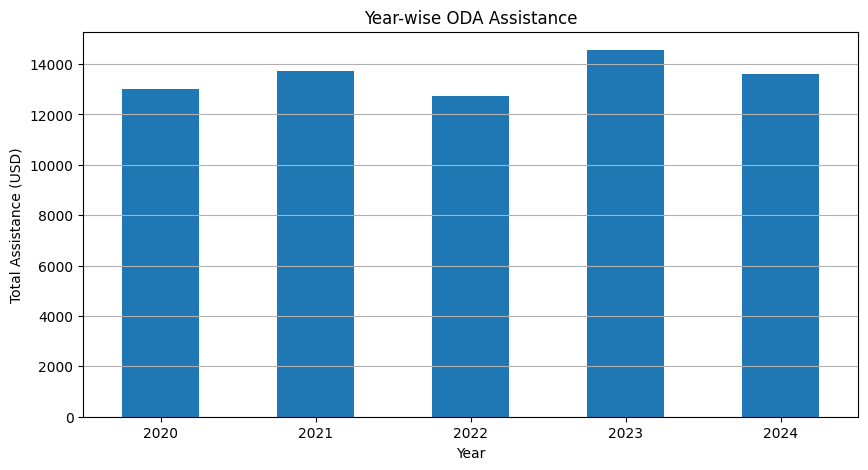

In [5]:
yearly = df.groupby("time_period")["obs_value"].sum()

plt.figure(figsize=(10,5))
yearly.plot(kind="bar")

plt.title("Year-wise ODA Assistance")
plt.xlabel("Year")
plt.ylabel("Total Assistance (USD)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

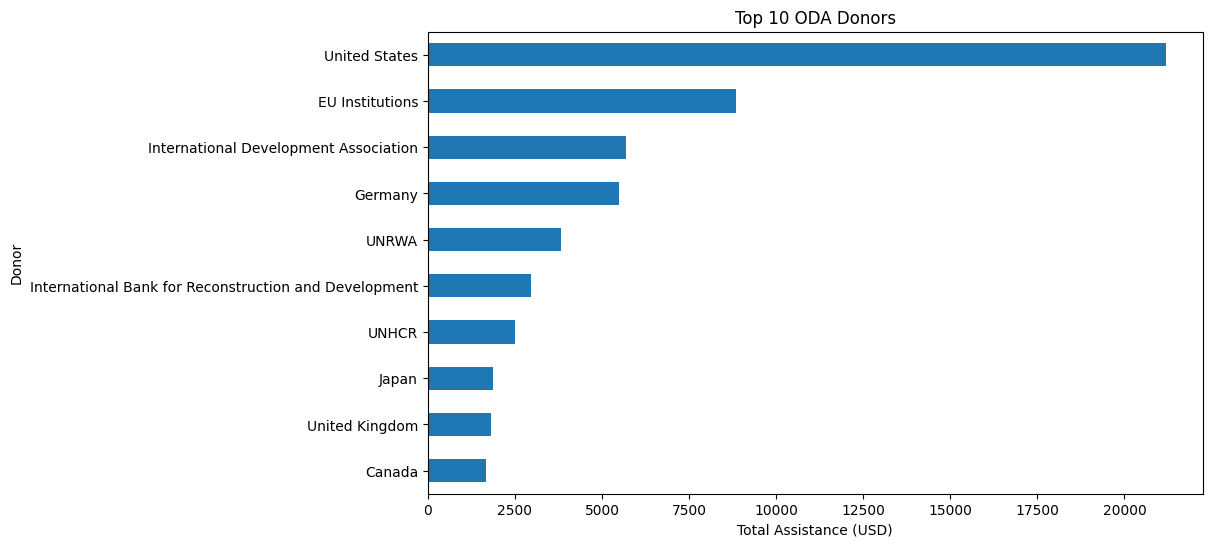

In [6]:
donors = df.groupby("donor_label")["obs_value"].sum()

top_donors = donors.sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))
top_donors.sort_values().plot(kind="barh")

plt.title("Top 10 ODA Donors")
plt.xlabel("Total Assistance (USD)")
plt.ylabel("Donor")
plt.show()

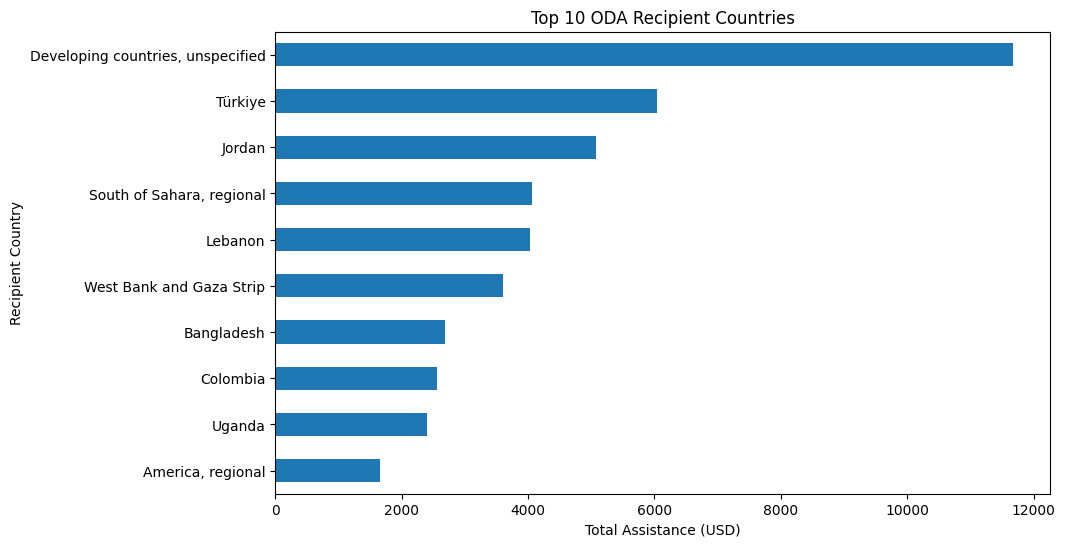

In [7]:
recipients = df.groupby("recipient_label")["obs_value"].sum()

top_recipients = recipients.sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))
top_recipients.sort_values().plot(kind="barh")

plt.title("Top 10 ODA Recipient Countries")
plt.xlabel("Total Assistance (USD)")
plt.ylabel("Recipient Country")
plt.show()

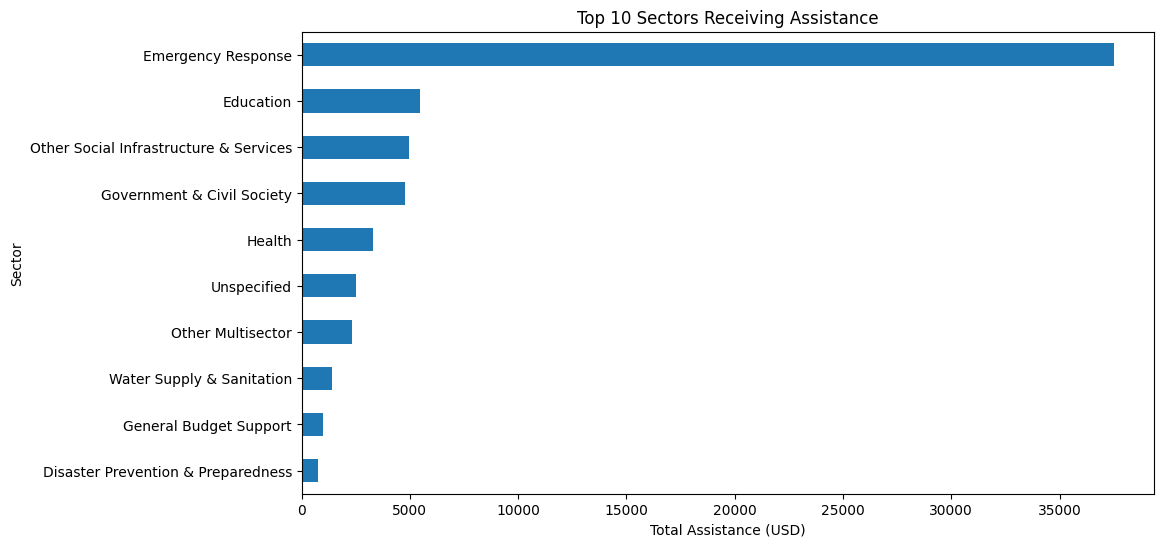

In [8]:
sector = df.groupby("sectorL1_label")["obs_value"].sum()

top_sector = sector.sort_values(ascending=False).head(10)

plt.figure(figsize=(11,6))
top_sector.sort_values().plot(kind="barh")

plt.title("Top 10 Sectors Receiving Assistance")
plt.xlabel("Total Assistance (USD)")
plt.ylabel("Sector")
plt.show()

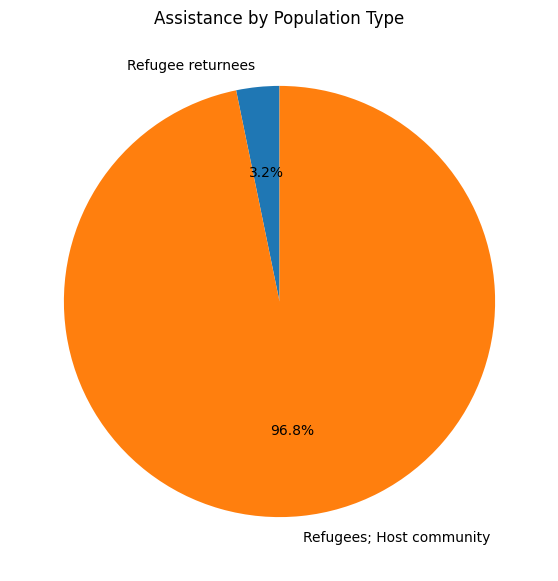

In [9]:
population = df.groupby("pop_type_label")["obs_value"].sum()

plt.figure(figsize=(7,7))

plt.pie(
    population,
    labels=population.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Assistance by Population Type")
plt.show()

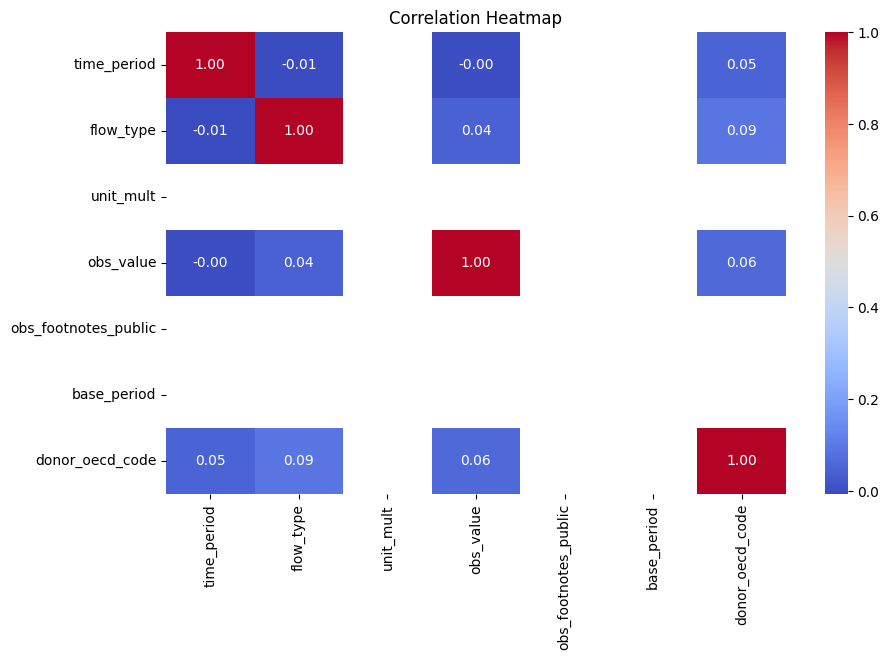

In [10]:
numeric = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,6))

sns.heatmap(
    numeric.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [11]:
print("PROJECT INSIGHTS")

print("\nTotal Financial Assistance:",
      df["obs_value"].sum())

print("\nYear with Highest Assistance:",
      yearly.idxmax())

print("\nTop Donor:",
      top_donors.idxmax())

print("\nTop Recipient:",
      top_recipients.idxmax())

print("\nTop Assistance Sector:",
      top_sector.idxmax())

PROJECT INSIGHTS

Total Financial Assistance: 67624.599442

Year with Highest Assistance: 2023

Top Donor: United States

Top Recipient: Developing countries, unspecified

Top Assistance Sector: Emergency Response


In [12]:
df.to_csv("cleaned_ODA_dataset.csv", index=False)

files.download("cleaned_ODA_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>